# Comparación de SVM inicial y optimizada con MLflow
## Demanda diaria de GROCERY I · Store Sales · Unidad 2

**Objetivo:** comparar la SVM de regresión inicial (`SVR`) con la seleccionada mediante
`GridSearchCV` usando las mismas fechas, variables y métricas. Registrar ambos modelos y las
16 combinaciones de la búsqueda en MLflow para revisar la comparación localmente.

Este cuaderno se basa en `main.py` y los módulos de `svm_demanda/`, con código autónomo y
explicaciones por etapa. Se predicen las ventas de **GROCERY I**, sumadas entre todas las
tiendas por día y expresadas en **miles de unidades**. No es clasificación: la familia ya
está elegida y se predice una cantidad.

**Uso:** abrir en VS Code/Jupyter, seleccionar el entorno del proyecto y ejecutar todas las
celdas en orden. Cada ejecución crea su carpeta en `resultados_cuaderno/`. Los CSV y los
resultados originales se conservan.

### 1. Entorno y dependencias

Si faltan dependencias, ejecutar en una celda y reiniciar el kernel:

```python
%pip install -r requirements.txt
```

**GridSearchCV es compatible con MLflow.** Se usa registro explícito para que ambos modelos
tengan las mismas métricas y cada candidato quede identificado. `autolog` también admite
GridSearchCV, pero aquí se desactiva para evitar registros duplicados. Los candidatos se
seleccionan solo con validación; la prueba final se usa después de esa selección.

In [1]:
from pathlib import Path
from time import perf_counter
from datetime import datetime
import hashlib
import importlib.metadata as metadata
import json
import platform
import subprocess
import sys
import time
import uuid
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import display, Markdown
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, ParameterGrid
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.18, "font.size": 10})
pd.set_option("display.max_columns", 12)
versiones = {p: metadata.version(p) for p in
             ["numpy", "pandas", "scikit-learn", "matplotlib", "mlflow", "ipykernel"]}
display(pd.Series(versiones, name="Versión").to_frame())
print("Python:", platform.python_version())

Python: 3.14.0


2026/11/12 11:55:11 INFO mlflow.agent.hint: Load the `mlflow-trace-instrumentation` skill at C:\Users\ASUS\AppData\Roaming\Python\Python314\site-packages\mlflow\assistant\skills\mlflow-trace-instrumentation\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


,Versión
numpy,2.4.2
pandas,3.0.0
scikit-learn,1.8.0
matplotlib,3.10.8
mlflow,3.18.0
ipykernel,7.2.0


### 2. Localizar los CSV y configurar la comparación

Se busca `train.csv` en `data/raw/` o en la carpeta `store-sales-time-series-forecasting*`
que ya existe dentro del repositorio. **No es necesario mover ni descargar de nuevo los CSV.**
Solo se necesita `train.csv`: el `test.csv` de Kaggle no contiene `sales`, por lo que no permite
calcular errores reales. Los demás archivos no intervienen en el modelo original.

Se conservan sus 7 días de historia, 35 variables, 80/20 temporal y su grilla. La variable
`fecha_especial` también se conserva, aunque sus fechas de 2019 no corresponden al historial
2013–2017 y queda inactiva. No equivale a los feriados del CSV auxiliar.

In [2]:
candidatas = [Path.cwd(), *Path.cwd().parents, Path.cwd() / "svm-demanda",
              Path.cwd() / "Repositorio TrABAJO U2" / "svm-demanda"]
BASE = next((p.resolve() for p in candidatas
             if (p / "svm_demanda" / "config.py").is_file()), None)
if BASE is None:
    raise FileNotFoundError("Abre el cuaderno desde svm-demanda o desde la carpeta del proyecto.")
rutas_csv = [BASE / "data" / "raw" / "train.csv"]
rutas_csv += sorted(BASE.glob("store-sales-time-series-forecasting*/train.csv"))
ARCHIVO_TRAIN = next((p for p in rutas_csv if p.is_file()), None)
if ARCHIVO_TRAIN is None:
    raise FileNotFoundError("No se encontró train.csv en data/raw/ ni en store-sales-time-series-forecasting*.")

FAMILIA = "GROCERY I"
VENTANA = 7
VARIABLES_HISTORIA = ["demanda", "dia_semana", "mes", "es_fin_de_semana", "fecha_especial"]
FECHAS_ESPECIALES = ["2019-01-01", "2019-02-14"]  # Configuración heredada.
FRACCION_PRUEBA = 0.20
N_PLIEGUES = 3
SEMILLA = 42
PARAM_GRID = {
    "modelSVM__C": [0.1, 1.0, 10.0, 100.0],
    "modelSVM__kernel": ["linear", "poly", "rbf", "sigmoid"],
    "modelSVM__epsilon": [0.1], "modelSVM__gamma": ["scale"],
}
GRUPO = datetime.now().strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:6]
SALIDA = BASE / "resultados_cuaderno" / GRUPO
SALIDA.mkdir(parents=True, exist_ok=True)
print("Dataset:", ARCHIVO_TRAIN)
print("Familia:", FAMILIA, "| combinaciones:", len(list(ParameterGrid(PARAM_GRID))))
print("Resultados de esta ejecución:", SALIDA)

Dataset: C:\Users\ASUS\Desktop\7mo Ciclo\Aprendizaje automático\Repositorio TrABAJO U2\svm-demanda\store-sales-time-series-forecasting (2)\train.csv
Familia: GROCERY I | combinaciones: 16
Resultados de esta ejecución: C:\Users\ASUS\Desktop\7mo Ciclo\Aprendizaje automático\Repositorio TrABAJO U2\svm-demanda\resultados_cuaderno\20261112_115511_5025bd


### 3. Cargar y revisar los datos

Se lee el CSV por bloques para reducir el consumo de memoria y solo se conserva GROCERY I.
Se suman sus ventas por día, se divide entre 1000 y se redondea a tres decimales, como en
`datos.cargar_diario()`.

El calendario se completa para que `lag1` siempre signifique **ayer**. Las fechas ausentes
se imputan con cero, como en el código original, y se marcan explícitamente: **un cero imputado
no demuestra que no hubo ventas**. Además de la comparación principal se informa el error
solo en días con respuesta observada.

In [3]:
bloques_familia = []
filas_csv = 0
for bloque in pd.read_csv(ARCHIVO_TRAIN,
                         usecols=["date", "store_nbr", "family", "sales"],
                         parse_dates=["date"], chunksize=200_000):
    filas_csv += len(bloque)
    bloques_familia.append(bloque.loc[bloque["family"].eq(FAMILIA)].copy())
ventas = pd.concat(bloques_familia, ignore_index=True)
del bloques_familia, bloque
if ventas.empty:
    raise ValueError(f"La familia {FAMILIA} no aparece en el CSV.")
if ventas[["date", "store_nbr", "sales"]].isna().any().any():
    raise ValueError("Hay datos nulos en las columnas necesarias.")
if ventas.duplicated(["date", "store_nbr", "family"]).any():
    raise ValueError("Hay registros duplicados de fecha, tienda y familia.")
if not np.isfinite(ventas["sales"]).all() or (ventas["sales"] < 0).any():
    raise ValueError("Las ventas contienen valores no finitos o negativos.")

serie = ventas.groupby("date")["sales"].sum().div(1000).round(3)
fechas = pd.date_range(serie.index.min(), serie.index.max(), freq="D")
fechas_ausentes = fechas.difference(serie.index)
diario = pd.DataFrame({"fecha": fechas, "producto": FAMILIA,
                       "demanda": serie.reindex(fechas, fill_value=0.0).to_numpy()})
diario["fecha_imputada"] = diario["fecha"].isin(fechas_ausentes)
display(pd.Series({"Filas del CSV": filas_csv, "Filas de GROCERY I": len(ventas),
    "Tiendas": ventas["store_nbr"].nunique(), "Días observados": len(serie),
    "Días del calendario completo": len(diario), "Días imputados con cero": len(fechas_ausentes),
    "Inicio": str(fechas.min().date()), "Fin": str(fechas.max().date())}, name="Valor").to_frame())
print("Fechas imputadas:", fechas_ausentes.strftime("%Y-%m-%d").tolist())
display(diario.head(8))
diario.to_csv(SALIDA / "demanda_diaria.csv", index=False)

Fechas imputadas: ['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']


,Valor
Filas del CSV,3000888
Filas de GROCERY I,90936
Tiendas,54
Días observados,1684
Días del calendario completo,1688
Días imputados con cero,4
Inicio,2013-01-01
Fin,2017-08-15


,fecha,producto,demanda,fecha_imputada
0,2013-01-01,GROCERY I,0.700,False
1,2013-01-02,GROCERY I,202.020,False
2,2013-01-03,GROCERY I,144.878,False
3,2013-01-04,GROCERY I,135.754,False
4,2013-01-05,GROCERY I,188.356,False
5,2013-01-06,GROCERY I,207.297,False
6,2013-01-07,GROCERY I,133.189,False
7,2013-01-08,GROCERY I,133.290,False


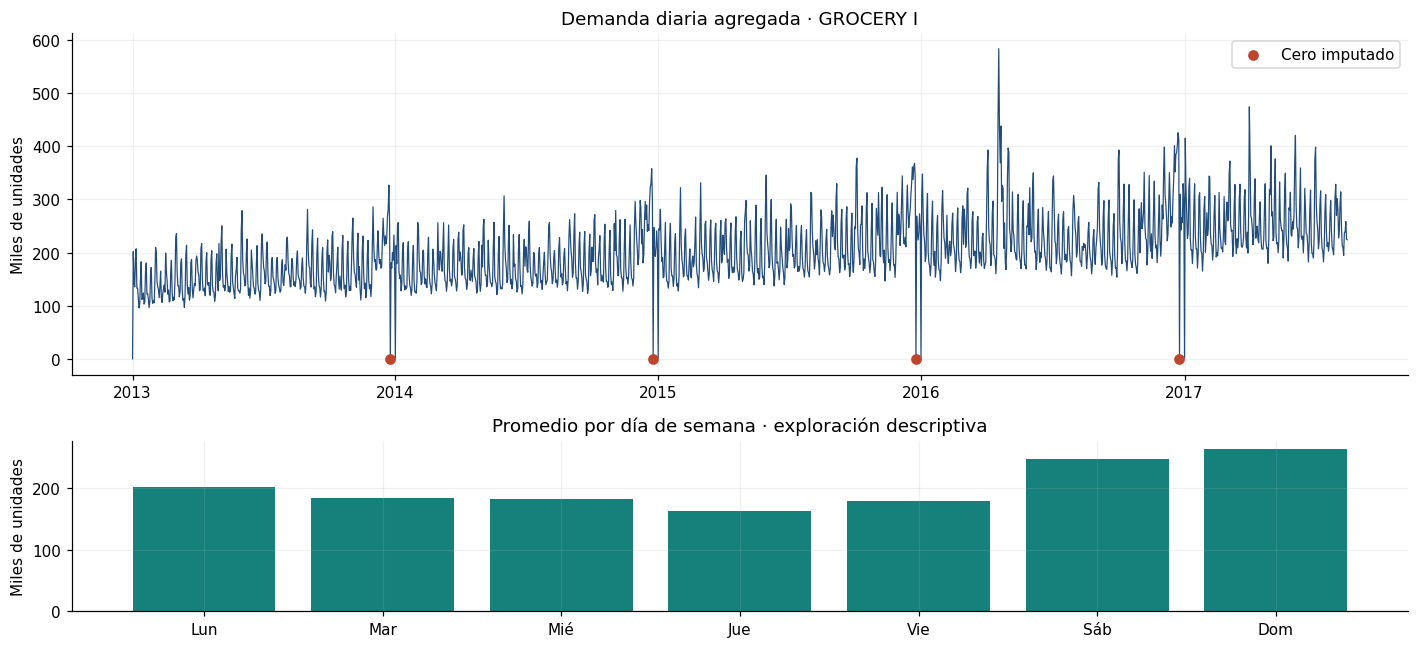

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6), height_ratios=[2, 1])
axes[0].plot(diario["fecha"], diario["demanda"], color="#224c7c", lw=0.8)
axes[0].scatter(diario.loc[diario.fecha_imputada, "fecha"],
                diario.loc[diario.fecha_imputada, "demanda"],
                color="#bd442d", label="Cero imputado", zorder=3)
axes[0].set(title=f"Demanda diaria agregada · {FAMILIA}", ylabel="Miles de unidades")
axes[0].legend()
promedios = diario.groupby(diario["fecha"].dt.dayofweek)["demanda"].mean()
axes[1].bar(["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"], promedios, color="#16817a")
axes[1].set(title="Promedio por día de semana · exploración descriptiva", ylabel="Miles de unidades")
fig.tight_layout()
fig.savefig(SALIDA / "exploracion.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

### 4. Crear las ventanas de siete días

Para predecir la demanda de **t** se usan cinco variables de **t−7 a t−1**.
`demanda_lag1` es la demanda de ayer y `demanda_lag7`, la de hace una semana.
La demanda de t es la respuesta `y`, nunca una entrada: **7 × 5 = 35 variables**.
Se eliminan las primeras siete filas porque no tienen historia suficiente.

In [5]:
diario["dia_semana"] = diario["fecha"].dt.dayofweek
diario["mes"] = diario["fecha"].dt.month
diario["es_fin_de_semana"] = (diario["dia_semana"] >= 5).astype(int)
diario["fecha_especial"] = diario["fecha"].isin(pd.to_datetime(FECHAS_ESPECIALES)).astype(int)
tabla = diario.copy()
columnas = []
for retraso in range(VENTANA, 0, -1):
    for variable in VARIABLES_HISTORIA:
        nombre = f"{variable}_lag{retraso}"
        tabla[nombre] = tabla.groupby("producto")[variable].shift(retraso)
        columnas.append(nombre)
tabla = tabla.dropna(subset=columnas).sort_values("fecha").reset_index(drop=True)
assert len(columnas) == VENTANA * len(VARIABLES_HISTORIA)
assert not tabla[columnas].isna().any().any()
assert np.isfinite(tabla[columnas].to_numpy()).all()
np.testing.assert_allclose(tabla["demanda_lag1"], diario["demanda"].shift(1).iloc[VENTANA:])
print("Filas utilizables:", len(tabla), "| variables:", len(columnas))
display(tabla[["fecha", "demanda_lag7", "demanda_lag2", "demanda_lag1", "demanda"]].head())

Filas utilizables: 1681 | variables: 35


,fecha,demanda_lag7,demanda_lag2,demanda_lag1,demanda
0,2013-01-08,0.700,207.297,133.189,133.290
1,2013-01-09,202.020,133.189,133.290,115.871
2,2013-01-10,144.878,133.290,115.871,96.200
3,2013-01-11,135.754,115.871,96.200,103.280
4,2013-01-12,188.356,96.200,103.280,151.025


### 5. Separar entrenamiento, validación y prueba por fecha

El 80 % más antiguo se usa para entrenar; el 20 % más reciente es la prueba final.
Dentro del entrenamiento se crean tres pliegues con `TimeSeriesSplit`: cada validación
ocurre después de su entrenamiento. El escalador se ajusta dentro de cada pliegue.

**Protocolo de un paso diario:** para predecir cada día de prueba se supone que ya se conocen
las ventas reales de ayer. El modelo permanece fijo y las entradas se actualizan con historia
observada. Se puede usar el día anterior de prueba como rezago sin entrenar con su respuesta.
Esto no equivale a predecir todos los meses desde una sola fecha: ese escenario exige otro
procedimiento y otra evaluación. `gap=0` corresponde a este horizonte de un día.

Entrenamiento: 1344 días | Prueba: 337 días desde 2016-09-13
Variables constantes en entrenamiento: ['fecha_especial_lag7', 'fecha_especial_lag6', 'fecha_especial_lag5', 'fecha_especial_lag4', 'fecha_especial_lag3', 'fecha_especial_lag2', 'fecha_especial_lag1']


,Pliegue,n_train,n_validacion,Train desde,Train hasta,Validación desde,Validación hasta
0,1,336,336,2013-01-08,2013-12-09,2013-12-10,2014-11-10
1,2,672,336,2013-01-08,2014-11-10,2014-11-11,2015-10-12
2,3,1008,336,2013-01-08,2015-10-12,2015-10-13,2016-09-12


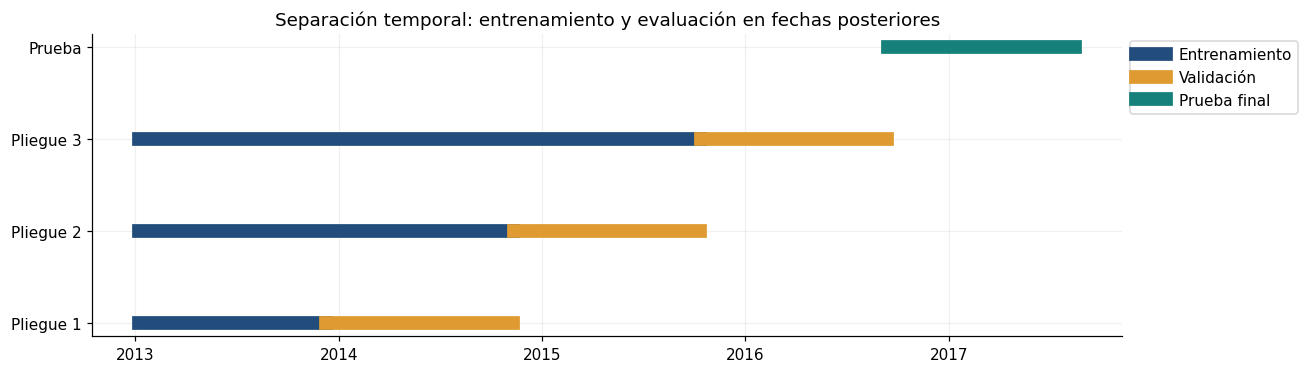

In [6]:
corte = int(len(tabla) * (1 - FRACCION_PRUEBA))
entrenamiento = tabla.iloc[:corte].reset_index(drop=True)
prueba = tabla.iloc[corte:].reset_index(drop=True)
X_train, y_train = entrenamiento[columnas], entrenamiento["demanda"]
X_test, y_test = prueba[columnas], prueba["demanda"]
fecha_prueba = prueba["fecha"].min()
pliegues = list(TimeSeriesSplit(n_splits=N_PLIEGUES, gap=0).split(X_train))
assert entrenamiento["fecha"].max() < fecha_prueba
assert (tabla["fecha"].diff().dropna() == pd.Timedelta(days=1)).all()
filas_particion = []
for i, (it, iv) in enumerate(pliegues, start=1):
    assert entrenamiento.loc[it, "fecha"].max() < entrenamiento.loc[iv, "fecha"].min()
    filas_particion.append({"Pliegue": i, "n_train": len(it), "n_validacion": len(iv),
        "Train desde": entrenamiento.loc[it, "fecha"].min().date(),
        "Train hasta": entrenamiento.loc[it, "fecha"].max().date(),
        "Validación desde": entrenamiento.loc[iv, "fecha"].min().date(),
        "Validación hasta": entrenamiento.loc[iv, "fecha"].max().date()})
particiones = pd.DataFrame(filas_particion)
print(f"Entrenamiento: {len(X_train)} días | Prueba: {len(X_test)} días desde {fecha_prueba.date()}")
display(particiones)
constantes = X_train.columns[X_train.nunique().eq(1)].tolist()
print("Variables constantes en entrenamiento:", constantes)
particiones.to_csv(SALIDA / "pliegues_temporales.csv", index=False)
fig, ax = plt.subplots(figsize=(12, 3.5))
for i, (it, iv) in enumerate(pliegues):
    ax.plot(entrenamiento.loc[it, "fecha"], np.full(len(it), i), lw=9,
             color="#224c7c", label="Entrenamiento" if i == 0 else None)
    ax.plot(entrenamiento.loc[iv, "fecha"], np.full(len(iv), i), lw=9,
             color="#df9b31", label="Validación" if i == 0 else None)
ax.plot(prueba["fecha"], np.full(len(prueba), N_PLIEGUES), lw=9,
         color="#16817a", label="Prueba final")
ax.set(yticks=range(N_PLIEGUES + 1), yticklabels=["Pliegue 1", "Pliegue 2", "Pliegue 3", "Prueba"],
       title="Separación temporal: entrenamiento y evaluación en fechas posteriores")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig(SALIDA / "particion_temporal.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

### 6. Entrenar la SVM inicial

El pipeline contiene `StandardScaler → SVR`, con `C=1`, kernel `rbf`, `epsilon=0.1` y
`gamma='scale'`. El escalador transforma las entradas; la demanda continúa en miles de unidades.
Colocar el escalador dentro del pipeline evita ajustarlo con datos de validación o prueba.

In [7]:
def crear_pipeline():
    return Pipeline([("scaler", StandardScaler()),
                     ("modelSVM", SVR(C=1.0, kernel="rbf", epsilon=0.1, gamma="scale"))])

mlflow.sklearn.autolog(disable=True)  # El registro será explícito en la sección 11.
tic = perf_counter()
modelo_inicial = crear_pipeline().fit(X_train, y_train)
tiempo_inicial = perf_counter() - tic
print(f"Ajuste de SVR inicial: {tiempo_inicial:.4f} s")
display(pd.Series(modelo_inicial.named_steps["modelSVM"].get_params(), name="Valor").to_frame())

Ajuste de SVR inicial: 0.2358 s


,Valor
C,1.0
cache_size,200
coef0,0.0
degree,3
epsilon,0.1
gamma,scale
kernel,rbf
max_iter,-1
shrinking,True
tol,0.001


### 7. Optimizar con GridSearchCV

| Parámetro | Valores | Función |
|---|---|---|
| C | 0.1, 1, 10, 100 | Controla la penalización del error |
| kernel | linear, poly, rbf, sigmoid | Define la relación aprendida |
| epsilon | 0.1, fijo | Margen sin penalización |
| gamma | scale, fijo | Actúa en kernels no lineales; no interviene en linear |

Son **16 candidatos × 3 pliegues = 48 ajustes**, más el reajuste del ganador con todo el
entrenamiento. Se selecciona el menor **RMSE promedio de validación**. Scikit-learn maximiza
scores; por eso se usa `neg_root_mean_squared_error` y luego se cambia el signo para mostrar
el RMSE positivo. La prueba no participa en la selección. Optimizar no garantiza mejorar en prueba.

In [8]:
busqueda = GridSearchCV(estimator=crear_pipeline(), param_grid=PARAM_GRID,
    scoring="neg_root_mean_squared_error", cv=pliegues, refit=True,
    return_train_score=True, error_score="raise", n_jobs=1, verbose=1)
tic = perf_counter()
busqueda.fit(X_train, y_train)
tiempo_busqueda = perf_counter() - tic
modelo_optimizado = busqueda.best_estimator_
resultados_cv = pd.DataFrame(busqueda.cv_results_)
resultados_cv["RMSE_CV"] = -resultados_cv["mean_test_score"]
resultados_cv["RMSE_train_CV"] = -resultados_cv["mean_train_score"]
resultados_cv.to_csv(SALIDA / "gridsearch.csv", index=False)
print("Mejores parámetros:", busqueda.best_params_)
print(f"Mejor RMSE CV: {-busqueda.best_score_:.4f} miles de unidades")
print(f"Búsqueda: {tiempo_busqueda:.3f} s | Reajuste del ganador: {busqueda.refit_time_:.4f} s")
display(resultados_cv[["rank_test_score", "param_modelSVM__C", "param_modelSVM__kernel",
                       "RMSE_train_CV", "RMSE_CV", "std_test_score"]]
        .sort_values("rank_test_score").round(4).reset_index(drop=True))

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Mejores parámetros: {'modelSVM__C': 1.0, 'modelSVM__epsilon': 0.1, 'modelSVM__gamma': 'scale', 'modelSVM__kernel': 'linear'}
Mejor RMSE CV: 34.5782 miles de unidades
Búsqueda: 8.124 s | Reajuste del ganador: 0.0713 s


,rank_test_score,param_modelSVM__C,param_modelSVM__kernel,RMSE_train_CV,RMSE_CV,std_test_score
0,1,1.0,linear,20.9121,34.5782,5.2312
1,2,10.0,linear,20.8459,35.7252,3.8745
2,3,100.0,rbf,16.9501,35.7537,8.3752
3,4,0.1,linear,22.0126,37.3171,5.6921
4,5,100.0,linear,20.6553,37.6740,3.3289
5,6,10.0,poly,20.2789,38.1203,5.0276
6,7,10.0,rbf,20.5705,41.4937,8.4970
7,8,1.0,sigmoid,25.4150,45.0829,7.0573
8,9,100.0,poly,16.2738,48.5859,20.0589
9,10,1.0,poly,28.7824,49.4093,8.1907


### 8. Evaluar ambos modelos en la misma prueba final

**MAE** es el error absoluto promedio; **RMSE** penaliza más los errores grandes. Ambos están
en miles de unidades y se prefieren menores. R² también se informa y puede ser negativo.
La persistencia (`venta estimada de hoy = venta real de ayer`) sirve como referencia sencilla.

Se distinguen el tiempo de ajuste y el de búsqueda completa. Para el ganador se utiliza
`refit_time_`; no se atribuyen los 48 ajustes a un solo entrenamiento. Las predicciones no se
recortan antes de evaluar, para mantener la comparación con el original.

In [9]:
def metricas(y_real, y_pred):
    return {"MAE": float(mean_absolute_error(y_real, y_pred)),
            "RMSE": float(np.sqrt(mean_squared_error(y_real, y_pred))),
            "R2": float(r2_score(y_real, y_pred))}

predicciones = prueba[["fecha", "producto", "demanda", "fecha_imputada"]].copy()
predicciones["SVR inicial"] = modelo_inicial.predict(X_test)
predicciones["SVR optimizada"] = modelo_optimizado.predict(X_test)
predicciones["Persistencia"] = X_test["demanda_lag1"].to_numpy()
filas_comparacion = []
for nombre, t_ajuste, t_busqueda in [("SVR inicial", tiempo_inicial, 0.0),
        ("SVR optimizada", busqueda.refit_time_, tiempo_busqueda), ("Persistencia", 0.0, 0.0)]:
    filas_comparacion.append({"Modelo": nombre, **metricas(y_test, predicciones[nombre]),
        "segundos_ajuste": t_ajuste, "segundos_busqueda": t_busqueda})
comparacion = pd.DataFrame(filas_comparacion).set_index("Modelo")
display(comparacion.round(4))
mejoras = {}
for metrica in ["MAE", "RMSE"]:
    inicial = comparacion.loc["SVR inicial", metrica]
    optimizada = comparacion.loc["SVR optimizada", metrica]
    mejoras[metrica] = 100 * (inicial - optimizada) / inicial if inicial else np.nan
    print(f"Reducción de {metrica}: {mejoras[metrica]:.2f}% (negativo = empeoramiento)")
comparacion.to_csv(SALIDA / "comparacion.csv")
predicciones.to_csv(SALIDA / "predicciones.csv", index=False)
observadas = ~predicciones["fecha_imputada"]
comparacion_observadas = pd.DataFrame({nombre: metricas(
    predicciones.loc[observadas, "demanda"], predicciones.loc[observadas, nombre])
    for nombre in comparacion.index}).T
print(f"Sensibilidad: {observadas.sum()} días con respuesta observada (sin ceros imputados):")
display(comparacion_observadas.round(4))
comparacion_observadas.to_csv(SALIDA / "comparacion_solo_dias_observados.csv")

Reducción de MAE: 48.45% (negativo = empeoramiento)
Reducción de RMSE: 29.38% (negativo = empeoramiento)
Sensibilidad: 336 días con respuesta observada (sin ceros imputados):


,MAE,RMSE,R2,segundos_ajuste,segundos_busqueda
Modelo,,,,,
SVR inicial,47.9854,66.4525,-0.1733,0.2358,0.0000
SVR optimizada,24.7379,46.9256,0.4150,0.0713,8.1241
Persistencia,45.9650,67.2776,-0.2026,0.0000,0.0000


,MAE,RMSE,R2
SVR inicial,47.5328,65.6503,-0.2017
SVR optimizada,23.5547,40.9607,0.5322
Persistencia,44.8721,63.4955,-0.1241


### 9. Revisar y reproducir las imágenes del repositorio

Se revisaron las tres imágenes de `resultados/`. Las nuevas figuras se calculan con esta ejecución.

| Figura original | Revisión aplicada |
|---|---|
| comparacion.png | Se aclara que el eje representa miles de unidades y se añade un acercamiento a los últimos 60 días. |
| optimizacion.png | Cada celda muestra el RMSE medio de CV; epsilon y gamma están fijos. El color logarítmico permite comparar sin que el candidato extremo oculte el resto. |
| importancia_caracteristicas.png | El código original usa el score por defecto de SVR (R²), pero el eje dice RMSE. Aquí se usa explícitamente neg_root_mean_squared_error para que la importancia sí sea aumento de RMSE. |

El mapa permite revisar por qué se eligió un candidato; la serie de prueba muestra qué ocurre
en las fechas posteriores que no participaron en la búsqueda.

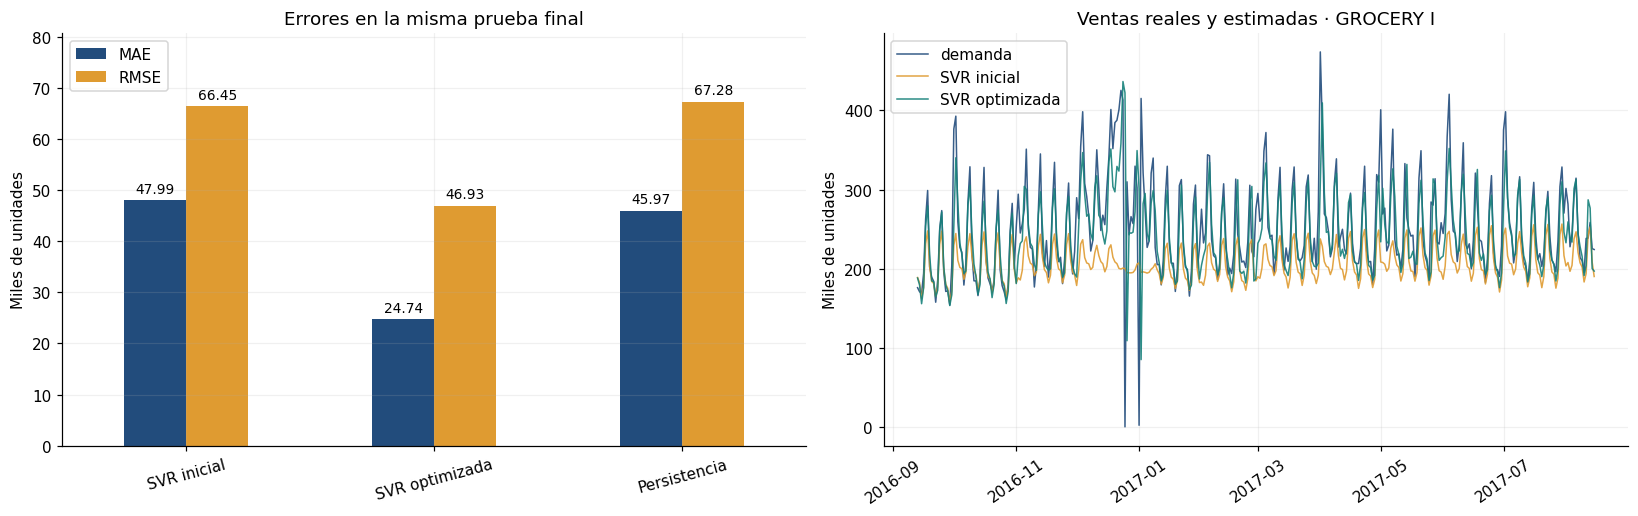

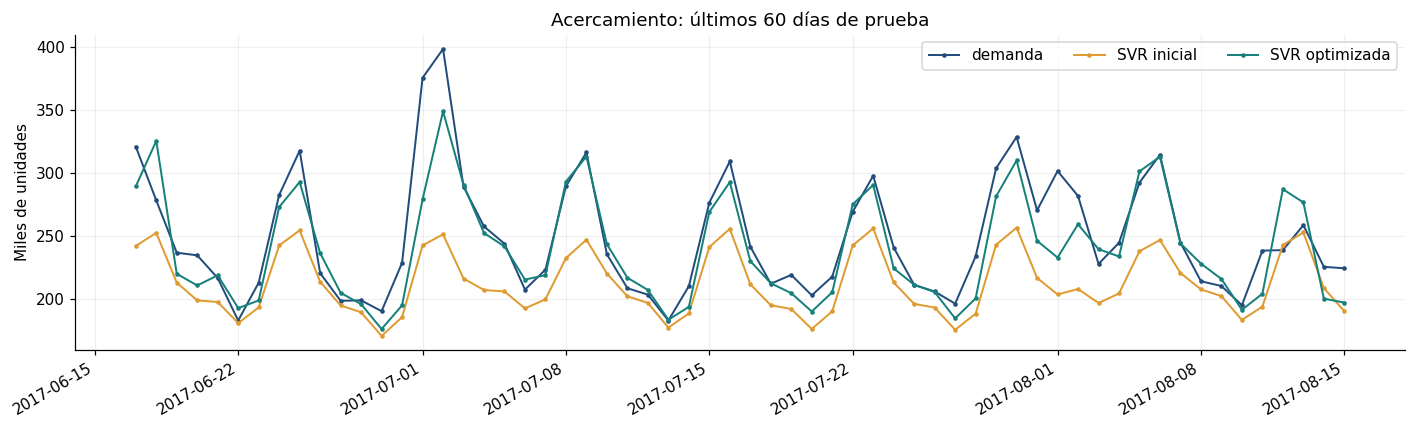

In [10]:
colores = {"demanda": "#224c7c", "SVR inicial": "#df9b31", "SVR optimizada": "#16817a"}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
comparacion[["MAE", "RMSE"]].plot.bar(ax=axes[0], rot=15, color=["#224c7c", "#df9b31"])
axes[0].set(title="Errores en la misma prueba final", ylabel="Miles de unidades", xlabel="")
for contenedor in axes[0].containers:
    axes[0].bar_label(contenedor, fmt="%.2f", padding=3, fontsize=9)
axes[0].set_ylim(0, comparacion[["MAE", "RMSE"]].to_numpy().max() * 1.2)
for nombre in ["demanda", "SVR inicial", "SVR optimizada"]:
    axes[1].plot(predicciones["fecha"], predicciones[nombre], label=nombre,
                 color=colores[nombre], lw=1.0, alpha=0.9)
axes[1].set(title=f"Ventas reales y estimadas · {FAMILIA}", ylabel="Miles de unidades")
axes[1].tick_params(axis="x", rotation=35)
axes[1].legend()
fig.tight_layout()
fig.savefig(SALIDA / "comparacion.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

vista = predicciones.tail(60)
fig, ax = plt.subplots(figsize=(13, 4))
for nombre in ["demanda", "SVR inicial", "SVR optimizada"]:
    ax.plot(vista["fecha"], vista[nombre], label=nombre, color=colores[nombre],
             marker=".", ms=4, lw=1.3)
ax.set(title="Acercamiento: últimos 60 días de prueba", ylabel="Miles de unidades")
ax.legend(ncol=3)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(SALIDA / "comparacion_ultimos_60_dias.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

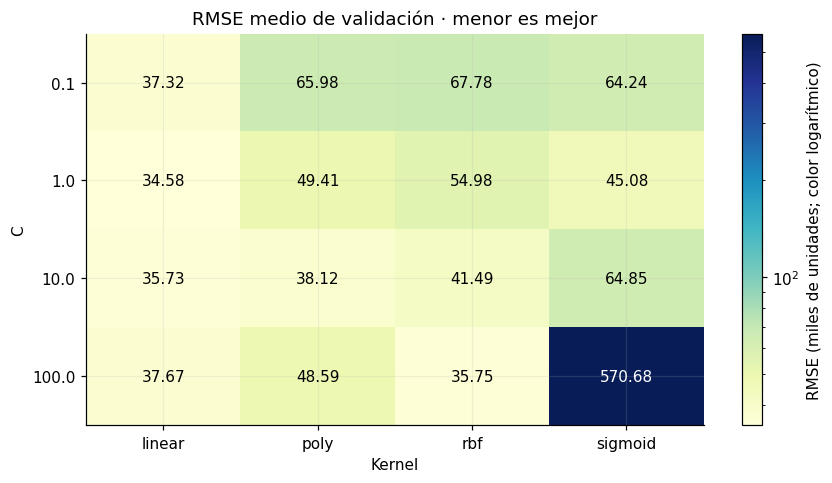

In [11]:
mapa = resultados_cv.pivot(index="param_modelSVM__C", columns="param_modelSVM__kernel",
                           values="RMSE_CV").reindex(columns=PARAM_GRID["modelSVM__kernel"])
fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(mapa.to_numpy(), cmap="YlGnBu", aspect="auto",
                norm=LogNorm(vmin=mapa.min().min(), vmax=mapa.max().max()))
ax.set_xticks(range(len(mapa.columns)), labels=mapa.columns)
ax.set_yticks(range(len(mapa.index)), labels=mapa.index)
ax.set(xlabel="Kernel", ylabel="C", title="RMSE medio de validación · menor es mejor")
for i in range(len(mapa.index)):
    for j in range(len(mapa.columns)):
        valor = mapa.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center",
                 color="white" if im.norm(valor) > 0.6 else "black")
fig.colorbar(im, ax=ax, label="RMSE (miles de unidades; color logarítmico)")
fig.tight_layout()
fig.savefig(SALIDA / "optimizacion.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

### 10. Interpretar el modelo optimizado

Se desordena una variable y se mide cuánto aumenta el RMSE. Un aumento grande indica que el
modelo depende de ella. Se repite diez veces y se muestran media y desviación estándar.
Se guardan todas las variables, incluso las de importancia cero o negativa.

Esta explicación se realiza después de evaluar: **no se usa la importancia de prueba para
volver a elegir variables o hiperparámetros**. Los rezagos están correlacionados y la permutación
individual no conserva toda la estructura temporal; sus resultados son orientativos, no causales.

,variable,aumento_RMSE,desviacion
0,demanda_lag1,13.9184,1.2708
1,dia_semana_lag7,2.7936,0.2885
2,es_fin_de_semana_lag7,2.4613,0.4220
3,es_fin_de_semana_lag2,1.4504,0.2770
4,demanda_lag7,0.9883,0.2557
5,dia_semana_lag5,0.6942,0.3130
6,mes_lag4,0.5027,0.2203
7,dia_semana_lag4,0.5005,0.1496
8,es_fin_de_semana_lag6,0.4863,0.1071
9,mes_lag6,0.4437,0.1707


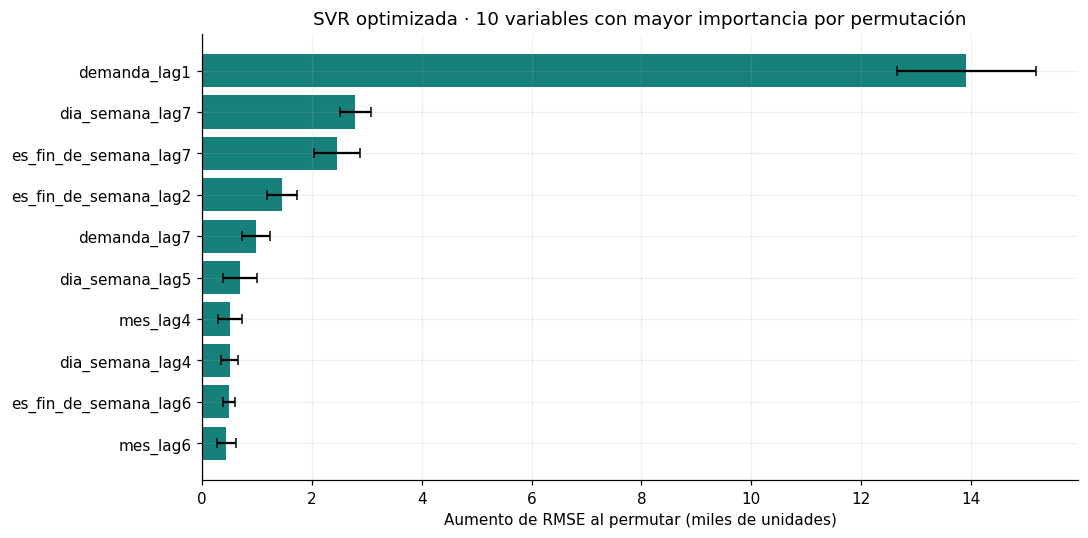

In [12]:
resultado_importancia = permutation_importance(modelo_optimizado, X_test, y_test,
    scoring="neg_root_mean_squared_error", n_repeats=10, random_state=SEMILLA, n_jobs=1)
importancias = pd.DataFrame({"variable": columnas,
    "aumento_RMSE": resultado_importancia.importances_mean,
    "desviacion": resultado_importancia.importances_std,
}).sort_values("aumento_RMSE", ascending=False)
importancias.to_csv(SALIDA / "importancia_caracteristicas.csv", index=False)
display(importancias.head(10).round(4).reset_index(drop=True))
top = importancias.head(10).sort_values("aumento_RMSE")
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top["variable"], top["aumento_RMSE"], xerr=top["desviacion"], color="#16817a", capsize=3)
ax.axvline(0, color="black", lw=0.7)
ax.set(title="SVR optimizada · 10 variables con mayor importancia por permutación",
       xlabel="Aumento de RMSE al permutar (miles de unidades)")
fig.tight_layout()
fig.savefig(SALIDA / "importancia_caracteristicas.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

### 11. Registrar la comparación en MLflow local

Se usa una base SQLite y un experimento propios. El servidor no necesita estar encendido
para guardar el registro; después se abre la interfaz con la misma base de datos.

Se crean **dos ejecuciones principales**, SVR inicial y SVR optimizada, con las mismas métricas
de prueba. Bajo la optimizada se guardan **16 ejecuciones hijas**, con los parámetros y el RMSE
de validación de cada candidato, su dispersión, sus pliegues y su posición en la búsqueda.
Los candidatos son registros de configuraciones; solo se guardan **dos pipelines entrenados**.

También se guardan gráficos, CSV, versiones, fechas de partición, columnas y la huella SHA-256
del archivo de datos. La etiqueta `comparacion` permite separar cada ejecución del cuaderno.

In [13]:
EXPERIMENTO = "Comparacion_SVR_GROCERY_I_Cuaderno"
MLFLOW_DB = BASE / "mlflow_cuaderno.db"
MLFLOW_ARTIFACTS = BASE / "mlartifacts_cuaderno"
TRACKING_URI = "sqlite:///" + MLFLOW_DB.as_posix()
MLFLOW_ARTIFACTS.mkdir(exist_ok=True)
mlflow.set_tracking_uri(TRACKING_URI)
mlflow.sklearn.autolog(disable=True)
if mlflow.active_run() is not None:
    raise RuntimeError("Hay una ejecución activa de MLflow. Finalízala antes de ejecutar esta celda.")
cliente = MlflowClient(tracking_uri=TRACKING_URI)
experimento = cliente.get_experiment_by_name(EXPERIMENTO)
if experimento is None:
    experiment_id = cliente.create_experiment(EXPERIMENTO, artifact_location=MLFLOW_ARTIFACTS.as_uri())
else:
    experiment_id = experimento.experiment_id
mlflow.set_experiment(experiment_id=experiment_id)
huella = hashlib.sha256()
with ARCHIVO_TRAIN.open("rb") as archivo:
    for bloque_bytes in iter(lambda: archivo.read(1024 * 1024), b""):
        huella.update(bloque_bytes)
sha256_csv = huella.hexdigest()
metadatos = {"grupo": GRUPO, "familia": FAMILIA, "unidad": "miles_de_unidades",
    "archivo_train": str(ARCHIVO_TRAIN.relative_to(BASE)), "sha256_train": sha256_csv,
    "ventana": VENTANA, "variables_historia": VARIABLES_HISTORIA, "columnas_modelo": columnas,
    "fechas_especiales_heredadas": FECHAS_ESPECIALES,
    "fechas_imputadas_cero": fechas_ausentes.strftime("%Y-%m-%d").tolist(),
    "inicio_train": str(entrenamiento.fecha.min().date()), "fin_train": str(entrenamiento.fecha.max().date()),
    "inicio_test": str(prueba.fecha.min().date()), "fin_test": str(prueba.fecha.max().date()),
    "protocolo": "un_paso_diario_con_historia_observada", "versiones": versiones,
    "python": platform.python_version(), "mejores_parametros": busqueda.best_params_,
    "param_grid": PARAM_GRID, "seed_permutation": SEMILLA}
(SALIDA / "metadatos_experimento.json").write_text(
    json.dumps(metadatos, ensure_ascii=False, indent=2), encoding="utf-8")

fila_inicial_cv = resultados_cv.loc[resultados_cv["param_modelSVM__C"].eq(1.0)
    & resultados_cv["param_modelSVM__kernel"].eq("rbf")]
assert len(fila_inicial_cv) == 1
cv_inicial = float(fila_inicial_cv.iloc[0]["RMSE_CV"])
requisitos_modelo = [f"{p}=={metadata.version(p)}" for p in
                     ["scikit-learn", "pandas", "numpy", "cloudpickle"]]
uris_modelos, run_ids = {}, {}
for nombre, modelo, cv_rmse in [("SVR inicial", modelo_inicial, cv_inicial),
        ("SVR optimizada", modelo_optimizado, -busqueda.best_score_)]:
    with mlflow.start_run(run_name=nombre) as ejecucion:
        run_ids[nombre] = ejecucion.info.run_id
        mlflow.set_tags({"comparacion": GRUPO, "tipo": "modelo_principal", "familia": FAMILIA,
            "dataset": "Store Sales", "unidad": "miles_de_unidades",
            "protocolo": "un_paso_diario", "sha256_train": sha256_csv})
        mlflow.log_params({**modelo.named_steps["modelSVM"].get_params(),
            "familia": FAMILIA, "ventana": VENTANA, "n_features": len(columnas),
            "n_train": len(X_train), "n_test": len(X_test), "n_pliegues": len(pliegues),
            "inicio_test": str(fecha_prueba.date()), "fraccion_prueba": FRACCION_PRUEBA,
            "scaler": "StandardScaler", "imputacion_fechas_ausentes": "cero_heredado"})
        fila = comparacion.loc[nombre]
        mlflow.log_metrics({"test_mae": fila["MAE"], "test_rmse": fila["RMSE"], "test_r2": fila["R2"],
            "cv_rmse": cv_rmse, "segundos_ajuste": fila["segundos_ajuste"],
            "segundos_busqueda": fila["segundos_busqueda"],
            "test_mae_solo_observados": comparacion_observadas.loc[nombre, "MAE"],
            "test_rmse_solo_observados": comparacion_observadas.loc[nombre, "RMSE"],
            "persistencia_test_rmse": comparacion.loc["Persistencia", "RMSE"]})
        mlflow.log_artifacts(str(SALIDA), artifact_path="resultados")
        ejemplo = X_train.head(3).copy()
        ejemplo.columns = pd.Index(ejemplo.columns, dtype=object)
        info = mlflow.sklearn.log_model(sk_model=modelo, name="pipeline_svr", input_example=ejemplo,
            signature=infer_signature(ejemplo, modelo.predict(ejemplo)), pip_requirements=requisitos_modelo)
        uris_modelos[nombre] = info.model_uri
        if nombre == "SVR optimizada":
            for indice, candidato in resultados_cv.iterrows():
                with mlflow.start_run(run_name=f"candidato_{indice:02d}", nested=True):
                    mlflow.set_tags({"comparacion": GRUPO, "tipo": "candidato_gridsearch",
                        "familia": FAMILIA, "seleccionado": str(indice == busqueda.best_index_)})
                    mlflow.log_params({k.replace("modelSVM__", ""): v
                                       for k, v in candidato["params"].items()})
                    mlflow.log_metrics({"cv_rmse": candidato["RMSE_CV"],
                        "cv_rmse_std": candidato["std_test_score"],
                        "cv_train_rmse": candidato["RMSE_train_CV"],
                        "rank": float(candidato["rank_test_score"]),
                        "mean_fit_time": candidato["mean_fit_time"],
                        **{f"cv_rmse_pliegue_{i+1}": -float(candidato[f"split{i}_test_score"])
                           for i in range(N_PLIEGUES)}})

indice_mlflow = {"tracking_uri": TRACKING_URI, "experiment_id": experiment_id,
    "grupo": GRUPO, "run_ids": run_ids, "model_uris": uris_modelos}
(SALIDA / "mlflow_runs.json").write_text(
    json.dumps(indice_mlflow, ensure_ascii=False, indent=2), encoding="utf-8")
for run_id in run_ids.values():
    cliente.log_artifact(run_id, str(SALIDA / "mlflow_runs.json"), artifact_path="resultados")
display(pd.DataFrame({"run_id": run_ids, "model_uri": uris_modelos}))
print("Registro completo: 2 modelos principales y", len(resultados_cv), "candidatos hijos.")

Registro completo: 2 modelos principales y 16 candidatos hijos.


,run_id,model_uri
SVR inicial,e31adc12104b4bf6a31b63f22c14513e,models:/m-74119e77f7da4784a01965bbd26824f9
SVR optimizada,16a915bfd5c44490bc7ae4b51436f959,models:/m-9590c58e8d324b5eb38d03f64563552a


### 12. Recuperar los modelos y verificar sus predicciones

Se consultan las ejecuciones de este grupo y se cargan ambos pipelines con las URI devueltas
por MLflow. Sus predicciones deben coincidir con las originales en toda la prueba.
Se muestran dos casos en fechas distintas con la historia real de sus siete días anteriores.

In [14]:
runs_grupo = mlflow.search_runs(experiment_ids=[experiment_id],
    filter_string=f"tags.comparacion = '{GRUPO}'", max_results=100)
principales = runs_grupo.loc[runs_grupo["tags.tipo"].eq("modelo_principal")]
candidatos_mlflow = runs_grupo.loc[runs_grupo["tags.tipo"].eq("candidato_gridsearch")]
assert len(principales) == 2 and len(candidatos_mlflow) == len(resultados_cv)
assert runs_grupo["status"].eq("FINISHED").all()
display(principales[["tags.mlflow.runName", "metrics.test_mae", "metrics.test_rmse",
                     "metrics.cv_rmse", "params.kernel", "params.C"]].round(4))
modelos_recuperados = {}
for nombre, original in [("SVR inicial", modelo_inicial), ("SVR optimizada", modelo_optimizado)]:
    recuperado = mlflow.sklearn.load_model(uris_modelos[nombre])
    np.testing.assert_allclose(recuperado.predict(X_test), original.predict(X_test), rtol=1e-10, atol=1e-10)
    modelos_recuperados[nombre] = recuperado
print("Verificación correcta: ambos modelos recuperados reproducen todas las predicciones de prueba.")
casos = prueba.loc[[0, len(prueba) - 1], ["fecha", "producto", "demanda"]].copy()
for nombre, recuperado in modelos_recuperados.items():
    casos[nombre] = recuperado.predict(X_test.iloc[[0, len(X_test) - 1]])
display(casos.reset_index(drop=True).round({"demanda": 3, "SVR inicial": 3, "SVR optimizada": 3}))
casos.to_csv(SALIDA / "dos_casos_modelos_recuperados.csv", index=False)
for run_id in run_ids.values():
    cliente.log_artifact(run_id, str(SALIDA / "dos_casos_modelos_recuperados.csv"), artifact_path="resultados")

Verificación correcta: ambos modelos recuperados reproducen todas las predicciones de prueba.


,tags.mlflow.runName,metrics.test_mae,metrics.test_rmse,metrics.cv_rmse,params.kernel,params.C
16,SVR optimizada,24.7379,46.9256,34.5782,linear,1.0
17,SVR inicial,47.9854,66.4525,54.9754,rbf,1.0


,fecha,producto,demanda,SVR inicial,SVR optimizada
0,2016-09-13,GROCERY I,175.935,188.785,188.133
1,2017-08-15,GROCERY I,224.208,190.069,196.922


### 13. Abrir la comparación en MLflow local

Para iniciar MLflow en **http://127.0.0.1:5002**, cambiar `INICIAR_UI` a `True` en la siguiente
celda y ejecutarla. Se inicia en segundo plano sin ventana de consola. El puerto 5002 separa
este experimento del servidor original (5001). Por defecto el inicio está desactivado:
el registro y la recuperación de los modelos funcionan sin servidor.

1. Abrir el experimento `Comparacion_SVR_GROCERY_I_Cuaderno`.
2. Filtrar por el grupo que imprime la celda y seleccionar las dos ejecuciones principales.
3. Usar **Compare** y revisar `test_mae`, `test_rmse`, `cv_rmse`, `kernel` y `C`.
4. Expandir la optimizada para comparar los 16 candidatos por `cv_rmse`.
5. En **Artifacts → resultados**, revisar gráficos y tablas; en **Models**, los pipelines.

Para iniciarlo manualmente otro día, desde `svm-demanda` y con el mismo entorno:

```powershell
python -m mlflow server --backend-store-uri sqlite:///mlflow_cuaderno.db --host 127.0.0.1 --port 5002 --no-serve-artifacts --workers 1
```

Se deben conservar la base SQLite y `mlartifacts_cuaderno/` para recuperar los modelos.

In [15]:
INICIAR_UI = False  # Cambiar a True para abrir la interfaz desde tu computadora.
PUERTO_UI = 5002
URL_UI = f"http://127.0.0.1:{PUERTO_UI}"

def responde_mlflow():
    try:
        with urlopen(URL_UI + "/health", timeout=1) as respuesta:
            return respuesta.status == 200
    except OSError:
        return False

if INICIAR_UI:
    if not responde_mlflow():
        comando = [sys.executable, "-m", "mlflow", "server", "--backend-store-uri", TRACKING_URI,
            "--default-artifact-root", MLFLOW_ARTIFACTS.as_uri(), "--host", "127.0.0.1",
            "--port", str(PUERTO_UI), "--no-serve-artifacts", "--workers", "1"]
        opciones = {"creationflags": subprocess.CREATE_NO_WINDOW} if sys.platform == "win32" else {}
        with (BASE / "mlflow_cuaderno.log").open("a", encoding="utf-8") as registro:
            proceso_ui_cuaderno = subprocess.Popen(comando, cwd=BASE, stdout=registro,
                stderr=subprocess.STDOUT, **opciones)
        (BASE / "mlflow_cuaderno.pid").write_text(str(proceso_ui_cuaderno.pid), encoding="utf-8")
        limite = time.monotonic() + 45
        while time.monotonic() < limite and not responde_mlflow():
            if proceso_ui_cuaderno.poll() is not None:
                break
            time.sleep(0.5)
    if not responde_mlflow():
        raise RuntimeError("MLflow no respondió. Revisa mlflow_cuaderno.log y si el puerto 5002 está ocupado.")
    cliente_http = MlflowClient(tracking_uri=URL_UI)
    run_servidor = cliente_http.get_run(run_ids["SVR optimizada"])
    assert run_servidor.data.tags["comparacion"] == GRUPO, "El puerto corresponde a otra base MLflow."
    display(Markdown(f"**MLflow disponible:** [{URL_UI}]({URL_UI})"))
    display(Markdown(f"[Abrir experimento]({URL_UI}/#/experiments/{experiment_id})"))
else:
    print("Interfaz desactivada; registros guardados en:", MLFLOW_DB)
print("Filtro de esta ejecución:", f"tags.comparacion = '{GRUPO}'")

Interfaz desactivada; registros guardados en: C:\Users\ASUS\Desktop\7mo Ciclo\Aprendizaje automático\Repositorio TrABAJO U2\svm-demanda\mlflow_cuaderno.db
Filtro de esta ejecución: tags.comparacion = '20261112_115511_5025bd'


El servidor continúa disponible al terminar. Para detener únicamente el proceso que inició
este kernel, cambiar `DETENER_UI` a `True` y ejecutar la siguiente celda.

In [16]:
DETENER_UI = False
if DETENER_UI and "proceso_ui_cuaderno" in globals():
    if proceso_ui_cuaderno.poll() is None:
        proceso_ui_cuaderno.terminate()
        proceso_ui_cuaderno.wait(timeout=15)
    print("Proceso MLflow iniciado por este kernel detenido.")

### 14. Contrastar con el original y redactar la conclusión

La tabla se compara con `resultados/comparacion.csv`, sin sobrescribirlo. Los valores se han
recalculado desde los datos; no se copian como resultados nuevos. Las diferencias pueden
deberse a datos, configuración o versiones. Los tiempos dependen de la computadora.

In [17]:
ruta_referencia = BASE / "resultados" / "comparacion.csv"
if ruta_referencia.is_file():
    referencia = pd.read_csv(ruta_referencia, index_col="Modelo")
    contraste = comparacion[["MAE", "RMSE"]].join(
        referencia[["MAE", "RMSE"]], lsuffix="_cuaderno", rsuffix="_original")
    contraste["diferencia_MAE"] = contraste["MAE_cuaderno"] - contraste["MAE_original"]
    contraste["diferencia_RMSE"] = contraste["RMSE_cuaderno"] - contraste["RMSE_original"]
    display(contraste.round(6))
    contraste.to_csv(SALIDA / "contraste_resultados_originales.csv")

kernel_ganador = busqueda.best_params_["modelSVM__kernel"]
c_ganador = busqueda.best_params_["modelSVM__C"]
rmse_inicial = comparacion.loc["SVR inicial", "RMSE"]
rmse_opt = comparacion.loc["SVR optimizada", "RMSE"]
rmse_persistencia = comparacion.loc["Persistencia", "RMSE"]
veredicto = "mejoró" if rmse_opt < rmse_inicial else "no mejoró"
referencia_simple = "superó" if rmse_opt < rmse_persistencia else "no superó"
conclusion = (
    f"Para **{FAMILIA}**, GridSearchCV eligió el kernel **{kernel_ganador}** con **C={c_ganador:g}**, "
    f"usando solo validación temporal. En prueba, la SVR optimizada **{veredicto}** el RMSE "
    f"de la inicial: pasó de **{rmse_inicial:.2f}** a **{rmse_opt:.2f} miles de unidades**, "
    f"una reducción de **{mejoras['RMSE']:.2f}%**. El MAE se redujo **{mejoras['MAE']:.2f}%**. "
    f"La optimizada **{referencia_simple}** la persistencia (RMSE: **{rmse_persistencia:.2f}**). "
    "Los resultados corresponden a un pronóstico de un día con historia real disponible y "
    "a la preparación heredada de fechas ausentes; no representan un pronóstico de varios meses "
    "emitido de una sola vez. Los dos pipelines se recuperaron de MLflow y reprodujeron sus predicciones."
)
display(Markdown(conclusion))
(SALIDA / "conclusion.md").write_text(conclusion, encoding="utf-8")
for run_id in run_ids.values():
    for archivo_final in [SALIDA / "conclusion.md", SALIDA / "contraste_resultados_originales.csv"]:
        if archivo_final.is_file():
            cliente.log_artifact(run_id, str(archivo_final), artifact_path="resultados")
print("Archivos generados:", SALIDA)

Archivos generados: C:\Users\ASUS\Desktop\7mo Ciclo\Aprendizaje automático\Repositorio TrABAJO U2\svm-demanda\resultados_cuaderno\20261112_115511_5025bd


,MAE_cuaderno,RMSE_cuaderno,MAE_original,RMSE_original,diferencia_MAE,diferencia_RMSE
Modelo,,,,,,
SVR inicial,47.985388,66.452502,47.9854,66.4525,-0.000012,0.000002
SVR optimizada,24.737908,46.925561,24.7379,46.9256,0.000008,-0.000039
Persistencia,45.965018,67.277587,45.9650,67.2776,0.000018,-0.000013


Para **GROCERY I**, GridSearchCV eligió el kernel **linear** con **C=1**, usando solo validación temporal. En prueba, la SVR optimizada **mejoró** el RMSE de la inicial: pasó de **66.45** a **46.93 miles de unidades**, una reducción de **29.38%**. El MAE se redujo **48.45%**. La optimizada **superó** la persistencia (RMSE: **67.28**). Los resultados corresponden a un pronóstico de un día con historia real disponible y a la preparación heredada de fechas ausentes; no representan un pronóstico de varios meses emitido de una sola vez. Los dos pipelines se recuperaron de MLflow y reprodujeron sus predicciones.

### Fuentes y alcance

- Código local: `main.py` y los módulos de `svm_demanda/`.
- Imágenes revisadas: `resultados/comparacion.png`, `optimizacion.png`, `importancia_caracteristicas.png`.
- [Scikit-learn: GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
- [Scikit-learn: TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html).
- [Scikit-learn: permutation_importance](https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html).
- [MLflow: integración con scikit-learn y búsquedas de parámetros](https://mlflow.org/docs/latest/api_reference/python_api/mlflow.sklearn.html).
- [MLflow: servidor local y almacenamiento](https://mlflow.org/docs/latest/tracking/server/).

No se añaden promociones, petróleo o feriados del CSV auxiliar porque cambiarían el experimento.
Las fechas especiales de 2019 y la imputación de días ausentes quedan documentadas como
limitaciones heredadas. Una siguiente versión puede evaluar esas decisiones usando únicamente
entrenamiento y validación.